In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('Campus_Selection.csv')

b_columns = [col for col in df.columns if col.endswith('_b')]
columns_to_drop = ['sl_no'] + b_columns
df_cleaned = df.drop(columns=columns_to_drop)

binary_mappings = {
    'gender': {'M': 1, 'F': 0},
    'workex': {'Yes': 1, 'No': 0},
    'specialisation': {'Mkt&HR': 1, 'Mkt&Fin': 0},
    'status': {'Placed': 1, 'Not Placed': 0}
}

for col, mapping in binary_mappings.items():
    if col in df_cleaned.columns:
        df_cleaned[col] = df_cleaned[col].map(mapping)

multi_cat_cols = ['hsc_s', 'degree_t']
df_processed = pd.get_dummies(
    df_cleaned, 
    columns=multi_cat_cols, 
    drop_first=True,  
    dtype=int
)

df_processed

,gender,ssc_p,hsc_p,degree_p,workex,etest_p,specialisation,mba_p,status,hsc_s_Commerce,hsc_s_Science,degree_t_Others,degree_t_Sci&Tech
0,1,67.00,91.00,58.00,0,55.0,1,58.80,1,1,0,0,1
1,1,79.33,78.33,77.48,1,86.5,0,66.28,1,0,1,0,1
2,1,65.00,68.00,64.00,0,75.0,0,57.80,1,0,0,0,0
3,1,56.00,52.00,52.00,0,66.0,1,59.43,0,0,1,0,1
4,1,85.80,73.60,73.30,0,96.8,0,55.50,1,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
210,1,80.60,82.00,77.60,0,91.0,0,74.49,1,1,0,0,0
211,1,58.00,60.00,72.00,0,74.0,0,53.62,1,0,1,0,1
212,1,67.00,67.00,73.00,1,59.0,0,69.72,1,1,0,0,0
213,0,74.00,66.00,58.00,0,70.0,1,60.23,1,1,0,0,0


In [2]:
y = df_processed['status']

cols_to_drop = ['status']
X = df_processed.drop(columns=cols_to_drop)

print("Размер матрицы X:", X.shape)
print("Размер вектора y:", y.shape)

Размер матрицы X: (215, 12)
Размер вектора y: (215,)


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print(f"Обучающая выборка: {X_train.shape[0]} строк")
print(f"Тестовая выборка: {X_test.shape[0]} строк")

Обучающая выборка: 172 строк
Тестовая выборка: 43 строк


In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)
acc_dt = accuracy_score(y_test, y_pred_dt)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)
acc_knn = accuracy_score(y_test, y_pred_knn)


print(f"Точность (Accuracy) Дерева решений: {acc_dt:.4f} ({acc_dt * 100:.2f}%)")
print(f"Точность (Accuracy) k-NN:           {acc_knn:.4f} ({acc_knn * 100:.2f}%)")

print("\n--- Подробный отчет для Дерева решений ---")
print(classification_report(y_test, y_pred_dt, target_names=['Not Placed', 'Placed']))

print("\n--- Подробный отчет для k-NN ---")
print(classification_report(y_test, y_pred_knn, target_names=['Not Placed', 'Placed']))

Точность (Accuracy) Дерева решений: 0.7674 (76.74%)
Точность (Accuracy) k-NN:           0.7209 (72.09%)

--- Подробный отчет для Дерева решений ---
              precision    recall  f1-score   support

  Not Placed       0.67      0.46      0.55        13
      Placed       0.79      0.90      0.84        30

    accuracy                           0.77        43
   macro avg       0.73      0.68      0.69        43
weighted avg       0.76      0.77      0.75        43


--- Подробный отчет для k-NN ---
              precision    recall  f1-score   support

  Not Placed       0.53      0.62      0.57        13
      Placed       0.82      0.77      0.79        30

    accuracy                           0.72        43
   macro avg       0.68      0.69      0.68        43
weighted avg       0.73      0.72      0.73        43



Размер матрицы X: (215, 12)
Размер вектора y: (215,)
Обучающая выборка: 172 строк
Тестовая выборка: 43 строк

Точность (Accuracy) Дерева решений: 0.7674 (76.74%)
Точность (Accuracy) k-NN:           0.7209 (72.09%)


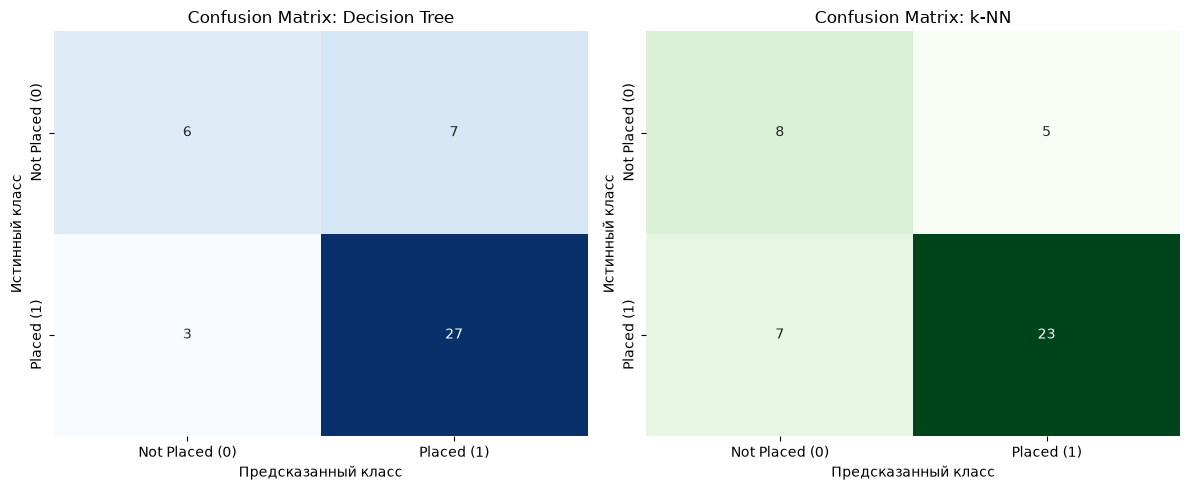

--- Decision Tree Classification Report ---
              precision    recall  f1-score   support

  Not Placed       0.67      0.46      0.55        13
      Placed       0.79      0.90      0.84        30

    accuracy                           0.77        43
   macro avg       0.73      0.68      0.69        43
weighted avg       0.76      0.77      0.75        43


--- k-NN Classification Report ---
              precision    recall  f1-score   support

  Not Placed       0.53      0.62      0.57        13
      Placed       0.82      0.77      0.79        30

    accuracy                           0.72        43
   macro avg       0.68      0.69      0.68        43
weighted avg       0.73      0.72      0.73        43



In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Загрузка и предобработка данных
df = pd.read_csv('Campus_Selection.csv')

b_columns = [col for col in df.columns if col.endswith('_b')]
columns_to_drop = ['sl_no'] + b_columns
df_cleaned = df.drop(columns=columns_to_drop)

binary_mappings = {
    'gender': {'M': 1, 'F': 0},
    'workex': {'Yes': 1, 'No': 0},
    'specialisation': {'Mkt&HR': 1, 'Mkt&Fin': 0},
    'status': {'Placed': 1, 'Not Placed': 0}
}

for col, mapping in binary_mappings.items():
    if col in df_cleaned.columns:
        df_cleaned[col] = df_cleaned[col].map(mapping)

multi_cat_cols = ['hsc_s', 'degree_t']
df_processed = pd.get_dummies(
    df_cleaned, 
    columns=multi_cat_cols, 
    drop_first=True,  
    dtype=int
)

# Исправлено: разделение X и y
y = df_processed['status']
X = df_processed.drop(columns=['status'])

print("Размер матрицы X:", X.shape)
print("Размер вектора y:", y.shape)

# 2. Разделение на train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print(f"Обучающая выборка: {X_train.shape[0]} строк")
print(f"Тестовая выборка: {X_test.shape[0]} строк")

# 3. Обучение моделей
# Decision Tree
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)
acc_dt = accuracy_score(y_test, y_pred_dt)

# k-NN с масштабированием
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
y_pred_knn = knn_model.predict(X_test_scaled)
acc_knn = accuracy_score(y_test, y_pred_knn)

# Вывод точности
print(f"\nТочность (Accuracy) Дерева решений: {acc_dt:.4f} ({acc_dt * 100:.2f}%)")
print(f"Точность (Accuracy) k-NN:           {acc_knn:.4f} ({acc_knn * 100:.2f}%)")

# 4. Построение матриц ошибок
cm_dt = confusion_matrix(y_test, y_pred_dt)
cm_knn = confusion_matrix(y_test, y_pred_knn)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
labels = ['Not Placed (0)', 'Placed (1)']

sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=labels, yticklabels=labels, cbar=False)
axes[0].set_title('Confusion Matrix: Decision Tree')
axes[0].set_xlabel('Предсказанный класс')
axes[0].set_ylabel('Истинный класс')

sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=labels, yticklabels=labels, cbar=False)
axes[1].set_title('Confusion Matrix: k-NN')
axes[1].set_xlabel('Предсказанный класс')
axes[1].set_ylabel('Истинный класс')

plt.tight_layout()
plt.show()

# 5. Подробные отчеты о классификации
print("--- Decision Tree Classification Report ---")
print(classification_report(y_test, y_pred_dt, target_names=['Not Placed', 'Placed']))

print("\n--- k-NN Classification Report ---")
print(classification_report(y_test, y_pred_knn, target_names=['Not Placed', 'Placed']))